# Assignment 5: Ensemble Learning and Performance Evaluation

* Name: Yashraj Ghule
* Div: E
* Batch: E1
* Roll no: 316
* PRN: 202401040319

**GITHUB REPO :-** https://github.com/Yashraj221B/AIML_TH_LAB/tree/main/C.A/Practical-05-Ensemble-Learning

**Aim:** Build Voting, AdaBoost and Stacking classifiers on the student placement data, evaluate them with several metrics and compare them with the individual models they are made of.

**Dataset:** `student_placement_dataset.csv` (1200 students, target `Placed`).

An ensemble combines several models so that their mistakes partly cancel out:

* **Voting:** several different models vote (hard voting) or their probabilities are averaged (soft voting).
* **AdaBoost:** weak models (small trees) are trained one after another and every new one pays more attention to the samples the earlier ones got wrong.
* **Stacking:** the predictions of several base models are used as the input of a final model (meta-learner) that learns how much to trust each of them.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("data/student_placement_dataset.csv")
print("Shape:", df.shape)
print(df["Placed"].value_counts().to_dict())
missing = df.isnull().sum()
print(missing[missing > 0].to_dict())
df.head()

Shape: (1200, 18)
{'No': 673, 'Yes': 527}
{'HSC_Percentage': 29, 'CGPA': 56, 'Internships': 50, 'Aptitude_Score': 81, 'Communication_Skill': 59, 'Coding_Hours_Per_Week': 100, 'City_Tier': 27, 'Family_Income_LPA': 131}


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,Male,Mechanical,85.2,75.9,7.17,2,0.0,3,1,65.0,Medium,1.8,Tier-3,Yes,7.98,No,No
1,STU1001,Male,IT,85.0,72.7,6.41,0,0.0,3,2,69.0,Low,2.5,Tier-3,No,12.46,Yes,Yes
2,STU1002,Female,Civil,79.7,85.1,7.46,1,1.0,2,0,72.0,Medium,7.3,Tier-3,Yes,5.70,No,Yes
3,STU1003,Female,Mechanical,81.6,67.0,4.51,1,1.0,0,3,63.0,Medium,20.3,Tier-2,Yes,3.68,No,No
4,STU1004,Male,Computer,70.5,78.8,8.19,0,0.0,2,0,62.0,High,3.5,Tier-1,No,18.97,Yes,Yes


Placed is 527 Yes and 673 No, so the classes are slightly unbalanced (about 44% placed), and 8 columns have missing values (up to 131 in Family_Income_LPA), so rows are not dropped and the values are filled in the pipeline.

## 3. Data preprocessing

* `Student_ID` is only an identifier, so it is dropped.
* Missing numbers are filled with the median and missing categories with the most frequent value.
* Numbers are standardised (needed by SVM, KNN and logistic regression) and categories are one-hot encoded.
* The target `Placed` is encoded as 0 (No) and 1 (Yes).
* The data is split 80:20 with stratification **before** fitting the imputer and scaler, and the preprocessing is part of a pipeline, so the test data never influences it.

In [3]:
X = df.drop(columns=["Placed", "Student_ID"])
le = LabelEncoder()
y = le.fit_transform(df["Placed"].str.strip())
print("Classes:", list(le.classes_))

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Placed share in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Classes: ['No', 'Yes']
Numeric: ['SSC_Percentage', 'HSC_Percentage', 'CGPA', 'Active_Backlogs', 'Internships', 'Projects', 'Certifications', 'Aptitude_Score', 'Coding_Hours_Per_Week', 'Family_Income_LPA']
Categorical: ['Gender', 'Branch', 'Communication_Skill', 'City_Tier', 'Hostel_Resident', 'Extracurricular']
Train: (960, 16) Test: (240, 16)
Placed share in train / test: 0.44 / 0.438


## 4. Evaluation metrics

* **Accuracy:** share of correct predictions.
* **Precision:** of the students predicted as placed, how many really were.
* **Recall:** of the students who were really placed, how many were found.
* **F1-score:** the harmonic mean of precision and recall.
* **ROC AUC:** how well the predicted probability separates placed from not placed students (0.5 is random, 1 is perfect).
* **Log loss:** quality of the predicted probabilities, lower is better.
* **5-fold cross validation accuracy:** the mean and the spread over 5 different splits of the training set, which is more reliable than one test split of 240 students.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make(model):
    return Pipeline([("prep", preprocessor), ("clf", model)])

results, fitted = [], {}

def evaluate(name, model):
    pipe = make(model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    cv_acc = cross_val_score(make(model), X_train, y_train, cv=cv, scoring="accuracy")
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
        "Log loss": log_loss(y_test, prob),
        "CV acc (mean)": cv_acc.mean(),
        "CV acc (std)": cv_acc.std(),
    })

# 5. Base models

These are the individual models that the ensembles are made of: SVM, Decision Tree (CART), KNN and Naive Bayes, plus Logistic Regression. Their settings are the same as the ones used in the classification assignment (tuned by cross validation on the training set).

In [5]:
base_models = {
    "SVM": SVC(kernel="linear", C=0.1, probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=51),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}
for name, model in base_models.items():
    evaluate(name, model)

pd.DataFrame(results).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,Log loss,CV acc (mean),CV acc (std)
Model,,,,,,,,
SVM,0.788,0.781,0.714,0.746,0.868,0.448,0.774,0.031
Decision Tree,0.750,0.765,0.619,0.684,0.788,0.547,0.673,0.016
KNN,0.767,0.769,0.667,0.714,0.862,0.506,0.729,0.023
Naive Bayes,0.746,0.704,0.724,0.714,0.836,0.542,0.732,0.022
Logistic Regression,0.775,0.758,0.714,0.735,0.865,0.451,0.772,0.033


# 6. Voting classifier

Hard voting takes the majority class. Soft voting averages the predicted probabilities and takes the class with the higher average. The voters are SVM, Decision Tree, KNN and Naive Bayes.

In [6]:
voters = [("svm", base_models["SVM"]), ("tree", base_models["Decision Tree"]),
          ("knn", base_models["KNN"]), ("nb", base_models["Naive Bayes"])]

# hard voting has no predict_proba, so its probability columns use the soft vote of the same models
hard = make(VotingClassifier(voters, voting="hard")).fit(X_train, y_train)
soft = make(VotingClassifier(voters, voting="soft")).fit(X_train, y_train)
fitted["Voting (hard)"], fitted["Voting (soft)"] = hard, soft

pred_hard = hard.predict(X_test)
prob_soft = soft.predict_proba(X_test)[:, 1]
cv_hard = cross_val_score(make(VotingClassifier(voters, voting="hard")), X_train, y_train, cv=cv, scoring="accuracy")
results.append({"Model": "Voting (hard)", "Accuracy": accuracy_score(y_test, pred_hard),
                "Precision": precision_score(y_test, pred_hard), "Recall": recall_score(y_test, pred_hard),
                "F1": f1_score(y_test, pred_hard), "ROC AUC": np.nan, "Log loss": np.nan,
                "CV acc (mean)": cv_hard.mean(), "CV acc (std)": cv_hard.std()})
evaluate("Voting (soft)", VotingClassifier(voters, voting="soft"))

pd.DataFrame(results).set_index("Model").loc[["Voting (hard)", "Voting (soft)"]].round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,Log loss,CV acc (mean),CV acc (std)
Model,,,,,,,,
Voting (hard),0.788,0.814,0.667,0.733,NaN,NaN,0.753,0.019
Voting (soft),0.788,0.776,0.724,0.749,0.861,0.469,0.747,0.025


# 7. AdaBoost

The weak learner is a decision stump (a tree of depth 1). First the number of boosting rounds is varied to see how the accuracy changes, then the best setting is chosen by cross validation on the training set.

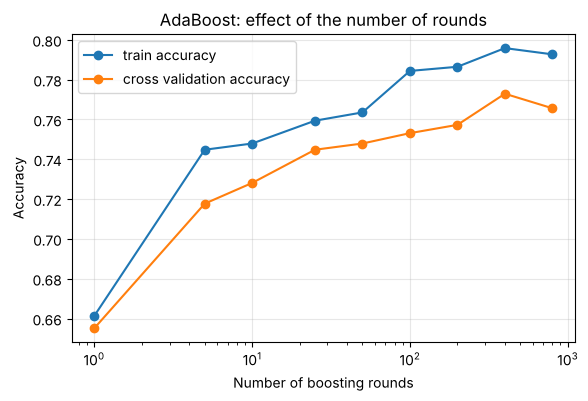

 rounds  train    cv
      1  0.661 0.655
      5  0.745 0.718
     10  0.748 0.728
     25  0.759 0.745
     50  0.764 0.748
    100  0.784 0.753
    200  0.786 0.757
    400  0.796 0.773
    800  0.793 0.766


In [7]:
rounds = [1, 5, 10, 25, 50, 100, 200, 400, 800]
train_acc, cv_acc_list = [], []
for n in rounds:
    ada = make(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=n, learning_rate=0.5, random_state=RANDOM_STATE))
    train_acc.append(ada.fit(X_train, y_train).score(X_train, y_train))
    cv_acc_list.append(cross_val_score(ada, X_train, y_train, cv=cv, scoring="accuracy").mean())

plt.figure(figsize=(6.5, 4))
plt.plot(rounds, train_acc, marker="o", label="train accuracy")
plt.plot(rounds, cv_acc_list, marker="o", label="cross validation accuracy")
plt.xscale("log")
plt.xlabel("Number of boosting rounds")
plt.ylabel("Accuracy")
plt.title("AdaBoost: effect of the number of rounds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(pd.DataFrame({"rounds": rounds, "train": train_acc, "cv": cv_acc_list}).round(3).to_string(index=False))

A single stump is weak (cross validation accuracy 0.655). Accuracy rises quickly in the first 25 rounds and keeps rising slowly, and the best cross validation accuracy is at 400 rounds (0.773). At 800 rounds the cross validation accuracy falls a little (0.766) while the train accuracy stays about the same, so more rounds stop helping and 400 was used. The gap between train (0.796) and cross validation accuracy is small, so AdaBoost with stumps overfits only slightly here.

In [8]:
best_n = rounds[int(np.argmax(cv_acc_list))]
print("Chosen number of rounds:", best_n)
evaluate("AdaBoost (stumps)", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=best_n, learning_rate=0.5, random_state=RANDOM_STATE))
pd.DataFrame(results).set_index("Model").loc[["AdaBoost (stumps)"]].round(3)

Chosen number of rounds: 400


,Accuracy,Precision,Recall,F1,ROC AUC,Log loss,CV acc (mean),CV acc (std)
Model,,,,,,,,
AdaBoost (stumps),0.767,0.775,0.657,0.711,0.848,0.601,0.773,0.02


Aptitude_Score           0.373
CGPA                     0.332
Active_Backlogs          0.086
Internships              0.048
Coding_Hours_Per_Week    0.037
Communication            0.035
Branch                   0.023
Projects                 0.022


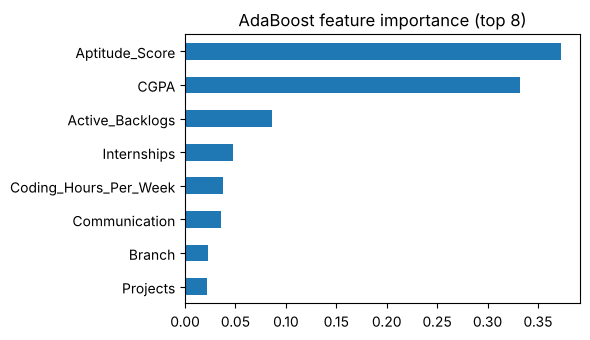

In [9]:
# which features does AdaBoost rely on? (importance summed over the one-hot columns of each original feature)
ada_fit = fitted["AdaBoost (stumps)"]
names = ada_fit.named_steps["prep"].get_feature_names_out()
imp = pd.Series(ada_fit.named_steps["clf"].feature_importances_, index=names)
imp = imp.groupby(lambda s: s.split("__")[1].split("_")[0] if s.startswith("cat") else s.split("__")[1]).sum()
imp = imp.sort_values(ascending=False).head(8)
print(imp.round(3).to_string())
imp[::-1].plot(kind="barh", figsize=(6, 3.5), title="AdaBoost feature importance (top 8)")
plt.tight_layout()
plt.show()

AdaBoost mostly uses Aptitude_Score (0.37) and CGPA (0.33), then Active_Backlogs (0.09). These are the same factors that the decision tree and the correlations picked in the classification assignment, so the boosted model agrees with the simpler ones on what matters.

## AdaBoost with different base classifiers

AdaBoost needs a base classifier that accepts sample weights. The same boosting (50 rounds, learning rate 0.5) is tried with a decision stump, a depth 3 tree, Naive Bayes, Logistic Regression and a linear SVM, to see which base classifier suits boosting best.

In [10]:
ada_bases = {
    "Stump (depth 1)": DecisionTreeClassifier(max_depth=1),
    "Tree (depth 3)": DecisionTreeClassifier(max_depth=3),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": SVC(kernel="linear", C=0.1),
}
rows = []
for name, base in ada_bases.items():
    ada = make(AdaBoostClassifier(base, n_estimators=50, learning_rate=0.5, random_state=RANDOM_STATE))
    ada.fit(X_train, y_train)
    rows.append({"Base classifier": name,
                 "Train accuracy": ada.score(X_train, y_train),
                 "Test accuracy": accuracy_score(y_test, ada.predict(X_test)),
                 "Test F1": f1_score(y_test, ada.predict(X_test)),
                 "CV accuracy": cross_val_score(ada, X_train, y_train, cv=cv, scoring="accuracy").mean()})
ada_bases_table = pd.DataFrame(rows).set_index("Base classifier")
ada_bases_table.round(3)

,Train accuracy,Test accuracy,Test F1,CV accuracy
Base classifier,,,,
Stump (depth 1),0.764,0.762,0.705,0.748
Tree (depth 3),0.791,0.775,0.719,0.750
Naive Bayes,0.770,0.742,0.708,0.747
Logistic Regression,0.773,0.758,0.707,0.771
Linear SVM,0.560,0.562,0.000,0.560


Boosting works with weak, simple learners. The stump, the depth 3 tree and Naive Bayes all give about 0.75 in cross validation after 50 rounds, and boosted Logistic Regression is the best (0.771), because it was already a good model. The linear SVM completely failed (accuracy 0.56, which is just the share of the majority class): scikit-learn's SVC treats the sample weights as a scaling of C, and AdaBoost starts with weights of 1/960, so the SVM was almost not fitted and predicted 'No' for everyone. This shows that a base classifier must accept sample weights in a meaningful way, and a strong, stable model such as an SVM is not a good choice for boosting.

# 8. Stacking classifier

The base models are SVM, Decision Tree, KNN and Naive Bayes. Their predicted probabilities (obtained by 5-fold cross validation inside the training set, so the meta-learner never sees predictions made on the data the base model was trained on) go into a Logistic Regression meta-learner.

In [11]:
stack_model = StackingClassifier(
    estimators=voters,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5, stack_method="predict_proba")
evaluate("Stacking", stack_model)
pd.DataFrame(results).set_index("Model").loc[["Stacking"]].round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,Log loss,CV acc (mean),CV acc (std)
Model,,,,,,,,
Stacking,0.796,0.792,0.724,0.756,0.869,0.457,0.771,0.024


SVM              4.008
Decision Tree    0.181
KNN              0.665
Naive Bayes      0.472


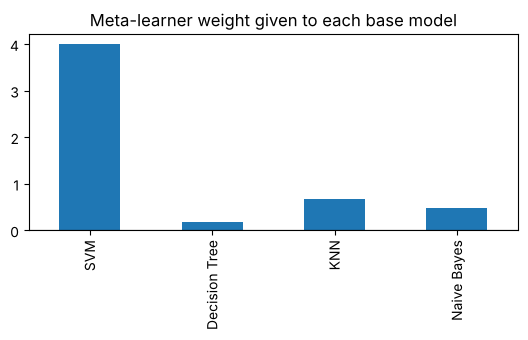

In [12]:
meta = fitted["Stacking"].named_steps["clf"].final_estimator_
weights = pd.Series(meta.coef_[0], index=["SVM", "Decision Tree", "KNN", "Naive Bayes"])
print(weights.round(3).to_string())
weights.plot(kind="bar", figsize=(5.5, 3.5), title="Meta-learner weight given to each base model")
plt.axhline(0, color="k", linewidth=0.8)
plt.tight_layout()
plt.show()

The meta-learner gives the SVM by far the largest weight (4.0), followed by KNN (0.67) and Naive Bayes (0.47), and almost nothing to the Decision Tree (0.18). So stacking mostly trusts the SVM, the strongest base model, and uses the others for small corrections.

# 9. Comparison of all models

In [13]:
order = ["SVM", "Decision Tree", "KNN", "Naive Bayes", "Logistic Regression",
         "Voting (hard)", "Voting (soft)", "AdaBoost (stumps)", "Stacking"]
table = pd.DataFrame(results).set_index("Model").loc[order]
table.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,Log loss,CV acc (mean),CV acc (std)
Model,,,,,,,,
SVM,0.788,0.781,0.714,0.746,0.868,0.448,0.774,0.031
Decision Tree,0.750,0.765,0.619,0.684,0.788,0.547,0.673,0.016
KNN,0.767,0.769,0.667,0.714,0.862,0.506,0.729,0.023
Naive Bayes,0.746,0.704,0.724,0.714,0.836,0.542,0.732,0.022
Logistic Regression,0.775,0.758,0.714,0.735,0.865,0.451,0.772,0.033
Voting (hard),0.788,0.814,0.667,0.733,NaN,NaN,0.753,0.019
Voting (soft),0.788,0.776,0.724,0.749,0.861,0.469,0.747,0.025
AdaBoost (stumps),0.767,0.775,0.657,0.711,0.848,0.601,0.773,0.020
Stacking,0.796,0.792,0.724,0.756,0.869,0.457,0.771,0.024


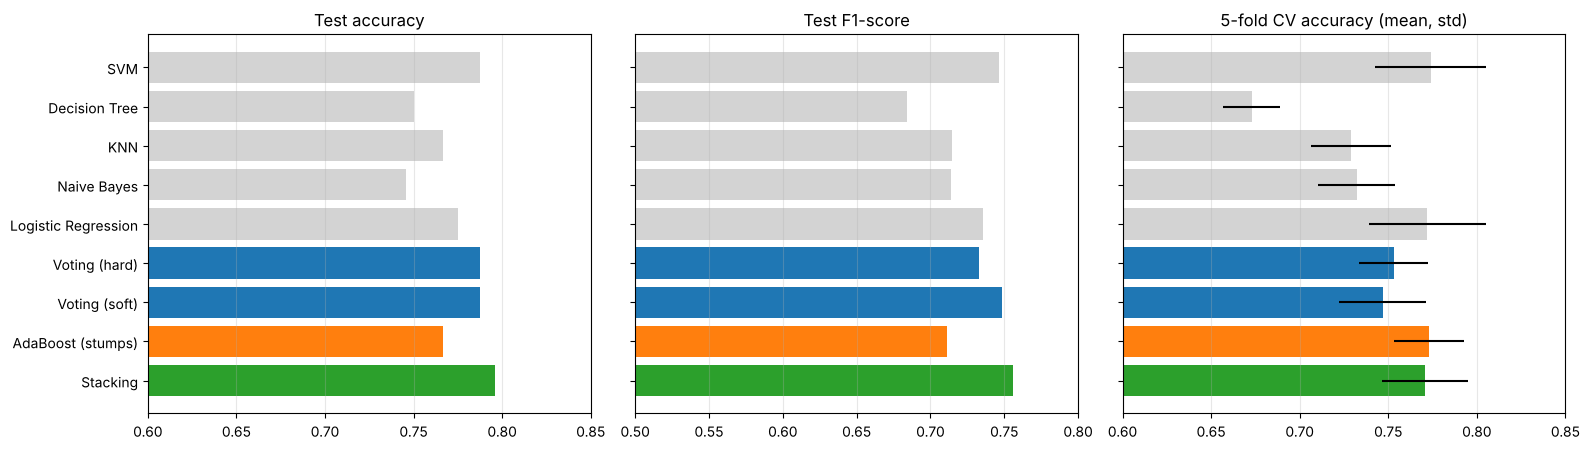

Grey = single models, blue = voting, orange = AdaBoost, green = stacking


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
colors = ["lightgray"] * 5 + ["tab:blue", "tab:blue", "tab:orange", "tab:green"]
ax[0].barh(order, table["Accuracy"], color=colors); ax[0].set_xlim(0.6, 0.85); ax[0].set_title("Test accuracy")
ax[1].barh(order, table["F1"], color=colors); ax[1].set_xlim(0.5, 0.8); ax[1].set_title("Test F1-score")
ax[2].barh(order, table["CV acc (mean)"], xerr=table["CV acc (std)"], color=colors); ax[2].set_xlim(0.6, 0.85); ax[2].set_title("5-fold CV accuracy (mean, std)")
for a in ax:
    a.invert_yaxis()
    a.grid(axis="x", alpha=0.3)
ax[1].set_yticklabels([]); ax[2].set_yticklabels([])
plt.tight_layout()
plt.show()
print("Grey = single models, blue = voting, orange = AdaBoost, green = stacking")

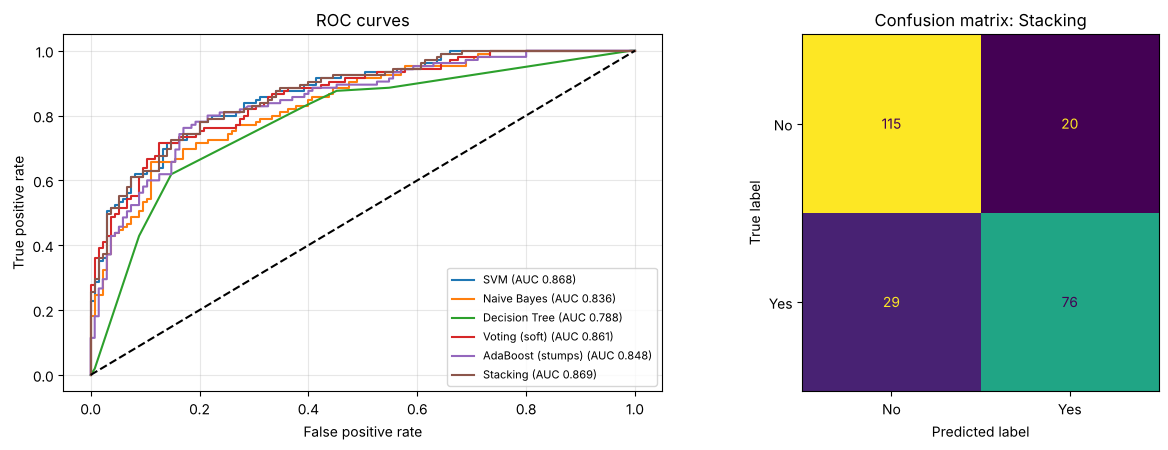

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for name in ["SVM", "Naive Bayes", "Decision Tree", "Voting (soft)", "AdaBoost (stumps)", "Stacking"]:
    prob = fitted[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

cm = confusion_matrix(y_test, fitted["Stacking"].predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax[1], colorbar=False, values_format="d")
ax[1].set_title("Confusion matrix: Stacking")
plt.tight_layout()
plt.show()

* **No ensemble is clearly better than the best single model.** Stacking has the best test accuracy (0.796), F1 (0.756) and AUC (0.869), but SVM is at 0.788, 0.746 and 0.868. The difference is 2 students out of 240, and in 5-fold cross validation SVM (0.774) is slightly ahead of AdaBoost (0.773) and Stacking (0.771). With a spread of about 0.02 to 0.03 between folds, these models cannot be separated.
* **The ensembles clearly beat the weak models they were built from.** The decision tree (CV 0.673), KNN (0.729) and Naive Bayes (0.732) are all lower than AdaBoost, Stacking and Voting.
* **Voting is dragged down by its weakest members.** Every voter has one equal vote, so the tree, KNN and Naive Bayes can outvote the better SVM, and its CV accuracy (0.753 hard, 0.747 soft) is below the SVM alone. Soft voting gave better recall (0.724) and probabilities than hard voting (0.667).
* **Stacking fixed this weakness** by learning the weights, and AdaBoost reached the same CV accuracy as the SVM using only depth-1 stumps. AdaBoost has the highest log loss (0.601), so its probabilities are the least well calibrated, and it also needed 400 rounds.
* The SVM, Logistic Regression and the stacked model have almost the same ROC curve, which suggests this dataset has a ceiling at around 78% accuracy that none of these methods can get past.

## 10. Do the ensembles gain from diversity?

An ensemble can only help if its members make different mistakes. This is checked with the correlation between the errors of the base models on the test set.

In [16]:
errors = pd.DataFrame({n: (fitted[n].predict(X_test) != y_test).astype(int)
                       for n in ["SVM", "Decision Tree", "KNN", "Naive Bayes"]})
print(errors.corr().round(2))
print()
print("Number of test errors:", errors.sum().to_dict())
both_wrong = (errors.sum(axis=1) == 4).sum()
any_wrong = (errors.sum(axis=1) >= 1).sum()
print(f"Students all 4 models get wrong: {both_wrong} | at least one model wrong: {any_wrong}")

                SVM  Decision Tree   KNN  Naive Bayes
SVM            1.00           0.45  0.65         0.66
Decision Tree  0.45           1.00  0.46         0.37
KNN            0.65           0.46  1.00         0.58
Naive Bayes    0.66           0.37  0.58         1.00

Number of test errors: {'SVM': 51, 'Decision Tree': 60, 'KNN': 56, 'Naive Bayes': 61}
Students all 4 models get wrong: 23 | at least one model wrong: 99


The errors of the models are fairly correlated (0.37 to 0.66), especially SVM with KNN (0.65) and Naive Bayes (0.66), so they tend to fail on the same students. 23 students are misclassified by all four models, and 99 by at least one. That is why combining them gives only a small gain: the ensemble can only fix the 76 students where the models disagree, and the 23 students that all of them get wrong are probably hard cases or are just not predictable from these features.

# 11. Conclusion

* **Voting** was the simplest to build but it was worse than the best member in cross validation (0.75 against 0.77), because weaker models have an equal vote. It would work better with models of similar strength or with weights.
* **AdaBoost** with 400 depth-1 trees made a very weak learner (accuracy 0.655) into a model as good as the SVM in cross validation (0.773). It is also easy to interpret through its feature importances (Aptitude_Score and CGPA).
* **Stacking** gave the best test scores (accuracy 0.796, F1 0.756, AUC 0.869) and learned to trust the SVM, but it is slower to train (every base model is trained 5 times more) and the improvement over the SVM is not significant.

On this dataset the gain from ensembling is small, because the models are fairly correlated in their errors and a linear SVM is already good. The ensembles would be most useful when the base models are different and strong, or when the single models are unstable (like the decision tree). Results are from one 240 student test set and 5-fold cross validation, so differences of about 1% should not be over-interpreted.

**When to use each ensemble method**

| Method | Use it when | Watch out for |
|---|---|---|
| Voting | You have a few models of similar strength and want a simple, robust combination. | A weak model has the same vote as a strong one, so remove or weight the weak ones. |
| AdaBoost | The base model is weak and simple (stumps or small trees) and the data has little noise. It also gives feature importance. | Sensitive to noisy labels and outliers, trains one round after another, and does not suit strong models like the SVM. |
| Stacking | You have several different, strong models and enough data to train a meta-learner with cross validation. | Slowest to train and hardest to explain, and the gain can be small if the models make the same errors. |

**Ethics and limits:** the dataset includes gender, city tier and family income, so a placement model could unfairly favour some groups. It should only help a placement cell, with a person making the decision. An ensemble is also harder to explain to a student than a single tree. Future work: try Random Forest and Gradient Boosting, tune the voting weights, and check the model separately for each gender and city tier.